In [ ]:
# CELL 1 - import library dan mapping dataset

from pathlib import Path
import yaml

BASE_DIR = Path(r"D:\1-Kuliah\SEKRIPSI\Skripsi_Traffic_Density_Estimation_and_Forecasting\03_Vehicle_Detection")
DATA_DIR = Path(r"D:\1-Kuliah\SEKRIPSI\Skripsi_Traffic_Density_Estimation_and_Forecasting\01_Datasets\New_YOLO_Datasets")

yaml_path = DATA_DIR / "data.yaml"

print("BASE_DIR ada :", BASE_DIR.exists())
print("DATA_DIR ada :", DATA_DIR.exists())
print("YAML ada     :", yaml_path.exists())

print("\nYAML path :", yaml_path)

BASE_DIR ada : True
DATA_DIR ada : True
YAML ada     : True

YAML path : D:\1-Kuliah\SEKRIPSI\Skripsi_Traffic_Density_Estimation_and_Forecasting\01_Datasets\New_YOLO_Datasets\data.yaml


In [ ]:
# CELL 2 - read isi data.yaml

with open(yaml_path, "r") as f:
    print(f.read())


path: D:/1-Kuliah/SEKRIPSI/Skripsi_Traffic_Density_Estimation_and_Forecasting/01_Datasets/New_YOLO_Datasets
train: D:\1-Kuliah\SEKRIPSI\Skripsi_Traffic_Density_Estimation_and_Forecasting\01_Datasets\New_YOLO_Datasets\train\images
val: D:\1-Kuliah\SEKRIPSI\Skripsi_Traffic_Density_Estimation_and_Forecasting\01_Datasets\New_YOLO_Datasets\valid\images
nc: 4
names:
  0: bus
  1: mobil
  2: motor
  3: truk
yaml_file: D:\1-Kuliah\SEKRIPSI\Traffic_Density_Estimation_and_Forecasting\01_Datasets\New_YOLO_Datasets\data.yaml
channels: 3



In [ ]:
# CELL 3 - membuat path data.yaml konsisten/absolute

# karena path masih relative, maka ubah menjadi absolute
import os

# 1. Baca file YAML yang sudah ada
with open(yaml_path, "r") as f:
    data = yaml.unsafe_load(f)

# 2. Ubah path train, val, dan test menjadi absolut
data['path']  = DATA_DIR.as_posix()
data['train'] = os.path.join(DATA_DIR, "train", "images")
data['val']   = os.path.join(DATA_DIR, "valid", "images")
# data['test']  = os.path.join(DATA_DIR, "test", "images")

# 3. Tulis kembali perubahan ke file YAML
with open(yaml_path, "w") as f:
    yaml.dump(data, f, sort_keys=False)

print("Path YAML berhasil diperbarui!\n")

with open(yaml_path, "r") as f:
    print(f.read())

Path YAML berhasil diperbarui!

path: D:/1-Kuliah/SEKRIPSI/Skripsi_Traffic_Density_Estimation_and_Forecasting/01_Datasets/New_YOLO_Datasets
train: D:\1-Kuliah\SEKRIPSI\Skripsi_Traffic_Density_Estimation_and_Forecasting\01_Datasets\New_YOLO_Datasets\train\images
val: D:\1-Kuliah\SEKRIPSI\Skripsi_Traffic_Density_Estimation_and_Forecasting\01_Datasets\New_YOLO_Datasets\valid\images
nc: 4
names:
  0: bus
  1: mobil
  2: motor
  3: truk
yaml_file: D:\1-Kuliah\SEKRIPSI\Traffic_Density_Estimation_and_Forecasting\01_Datasets\New_YOLO_Datasets\data.yaml
channels: 3



In [ ]:
# CELL 4 - mengecek total gambar di masing masing folder
print("Rincian jumlah gambar di masing-masing folder:")

splits = ['train', 'valid', 'test'] 
valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
total_semua = 0

for split in splits:
    folder_path = os.path.join(DATA_DIR, split, "images")
    
    if os.path.exists(folder_path):
        jumlah = len([f for f in os.listdir(folder_path) if f.lower().endswith(valid_extensions)])
        print(f"• {split:<7}/images : {jumlah} gambar")
        total_semua += jumlah
    else:
        print(f"• {split:<7}/images : (Folder tidak ditemukan)")

print("-" * 30)
print(f"Total Keseluruhan : {total_semua} gambar")

Rincian jumlah gambar di masing-masing folder:
• train  /images : 2400 gambar
• valid  /images : 200 gambar
• test   /images : (Folder tidak ditemukan)
------------------------------
Total Keseluruhan : 2600 gambar


In [ ]:
# CELL 5 - KONFIGURASI ROI

import numpy as np
import cv2
import torch

from copy import copy
from ultralytics import YOLO
from ultralytics.models.yolo.detect import DetectionTrainer, DetectionValidator
from ultralytics.utils import ops

# Resolusi referensi saat polygon dibuat
ROI_REF_W = 1280
ROI_REF_H = 720

ROI_IN = [
    (497, 234), (40, 280), (124, 718), (1181, 535)
]

ROI_OUT = [
    (642, 263), (1102, 144), (1265, 172), (1261, 511)
]

ROIS = {
    "IN": ROI_IN,
    "OUT": ROI_OUT
}

print("ROI IN :", ROI_IN)
print("ROI OUT:", ROI_OUT)

ROI IN : [(497, 234), (40, 280), (124, 718), (1181, 535)]
ROI OUT: [(642, 263), (1102, 144), (1265, 172), (1261, 511)]


In [8]:
# CELL 6 - FUNGSI FILTER ROI

def scale_roi(ori_shape):
    """Sesuaikan polygon dengan resolusi asli gambar."""
    h, w = int(ori_shape[0]), int(ori_shape[1])

    sx = w / ROI_REF_W
    sy = h / ROI_REF_H

    polygons = {}

    for name, points in ROIS.items():
        polygon = np.array(points, dtype=np.float32)
        polygon[:, 0] *= sx
        polygon[:, 1] *= sy

        polygons[name] = polygon

    return polygons


def filter_boxes_roi(boxes_xyxy, img_shape, ori_shape, ratio_pad):
    """
    Menghasilkan mask boolean untuk bounding box.

    True  = titik tengah berada dalam ROI IN atau OUT
    False = titik tengah berada di luar kedua ROI

    boxes_xyxy: koordinat pada gambar input YOLO (letterbox).
    """

    n = len(boxes_xyxy)

    if n == 0:
        return torch.zeros(
            0, dtype=torch.bool, device=boxes_xyxy.device
        )

    # Kembalikan koordinat bbox ke ukuran gambar asli
    boxes_original = ops.scale_boxes(
        img_shape,
        boxes_xyxy.clone(),
        ori_shape,
        ratio_pad=ratio_pad
    )

    # Hitung titik tengah bbox
    centers = (
        boxes_original[:, :2] + boxes_original[:, 2:]
    ) / 2

    centers = centers.detach().float().cpu().numpy()

    polygons = scale_roi(ori_shape)

    keep = []

    for cx, cy in centers:
        inside = any(
            cv2.pointPolygonTest(
                polygon,
                (float(cx), float(cy)),
                False
            ) >= 0
            for polygon in polygons.values()
        )

        keep.append(inside)

    return torch.tensor(
        keep,
        dtype=torch.bool,
        device=boxes_xyxy.device
    )

In [ ]:
# CELL 7 - CUSTOM ROI VALIDATOR dengan FILTER GT SEBELUM LOSS + FILTER PREDIKSI SEBELUM METRIK

from ultralytics.utils import LOGGER
import torch
import numpy as np


class ROIValidator(DetectionValidator):

    def init_metrics(self, model):
        super().init_metrics(model)

        self.total_gt = 0
        self.total_gt_roi = 0
        self.total_pred_roi = 0

    
    # 1. PREPROCESS - FILTER GROUND TRUTH SEBELUM LOSS
    def preprocess(self, batch):

        batch = super().preprocess(batch)

        img_shape = batch["img"].shape[2:]

        keep_gt = torch.zeros(
            len(batch["cls"]),
            dtype=torch.bool,
            device=batch["bboxes"].device
        )

        batch_idx = batch["batch_idx"].reshape(-1)

        # Proses setiap gambar dalam batch
        for si in range(len(batch["img"])):

            gt_idx = torch.where(batch_idx == si)[0]

            if len(gt_idx) == 0:
                continue

            # Normalized XYWH -> pixel XYXY
            gt_boxes = ops.xywh2xyxy(
                batch["bboxes"][gt_idx].clone()
            )

            h, w = img_shape

            gain = gt_boxes.new_tensor([w, h, w, h])
            gt_boxes *= gain

            # Filter GT berdasarkan ROI
            gt_mask = filter_boxes_roi(
                gt_boxes,
                img_shape,
                batch["ori_shape"][si],
                batch["ratio_pad"][si]
            )

            keep_gt[gt_idx] = gt_mask

        # Statistik ground truth
        self.total_gt += len(batch["cls"])
        self.total_gt_roi += int(keep_gt.sum().item())

        # Filter anotasi SEBELUM loss dihitung
        batch["cls"] = batch["cls"][keep_gt]
        batch["bboxes"] = batch["bboxes"][keep_gt]
        batch["batch_idx"] = batch["batch_idx"][keep_gt]

        return batch

    
    # 2. UPDATE METRICS - FILTER PREDIKSI BERDASARKAN ROI
    def update_metrics(self, preds, batch):

        if not all(isinstance(p, dict) for p in preds):
            raise RuntimeError(
                "Format prediksi tidak kompatibel. "
                "Periksa versi Ultralytics."
            )

        img_shape = batch["img"].shape[2:]

        for si, pred in enumerate(preds):

            pred_mask = filter_boxes_roi(
                pred["bboxes"],
                img_shape,
                batch["ori_shape"][si],
                batch["ratio_pad"][si]
            )

            n_pred = len(pred["bboxes"])

            # Filter field prediksi
            preds[si] = {
                key: (
                    value[pred_mask]
                    if isinstance(value, torch.Tensor)
                    and value.ndim > 0
                    and len(value) == n_pred
                    else value
                )
                for key, value in pred.items()
            }

            self.total_pred_roi += int(
                pred_mask.sum().item()
            )

        # Ground truth sudah difilter pada preprocess
        super().update_metrics(preds, batch)

    
    # 3. STATISTIK ROI
    def get_stats(self):

        if self.total_gt_roi == 0:
            raise ValueError(
                "Tidak ada ground truth di dalam ROI. "
                "Periksa koordinat polygon dan resolusi."
            )

        LOGGER.info(
            f"ROI Validation | "
            f"GT total: {self.total_gt} | "
            f"GT dalam ROI: {self.total_gt_roi} | "
            f"Prediksi dalam ROI: {self.total_pred_roi}"
        )

        return super().get_stats()


print("ROIValidator dengan filter Ground Truth sebelum loss berhasil dibuat.")


ROIValidator dengan filter Ground Truth sebelum loss berhasil dibuat.


In [10]:
# CELL 8 - CUSTOM ROI TRAINER

class ROITrainer(DetectionTrainer):

    def get_validator(self):

        return ROIValidator(
            self.test_loader,
            save_dir=self.save_dir,
            args=copy(self.args),
            _callbacks=self.callbacks
        )


print("ROITrainer berhasil didefinisikan.")

ROITrainer berhasil didefinisikan.


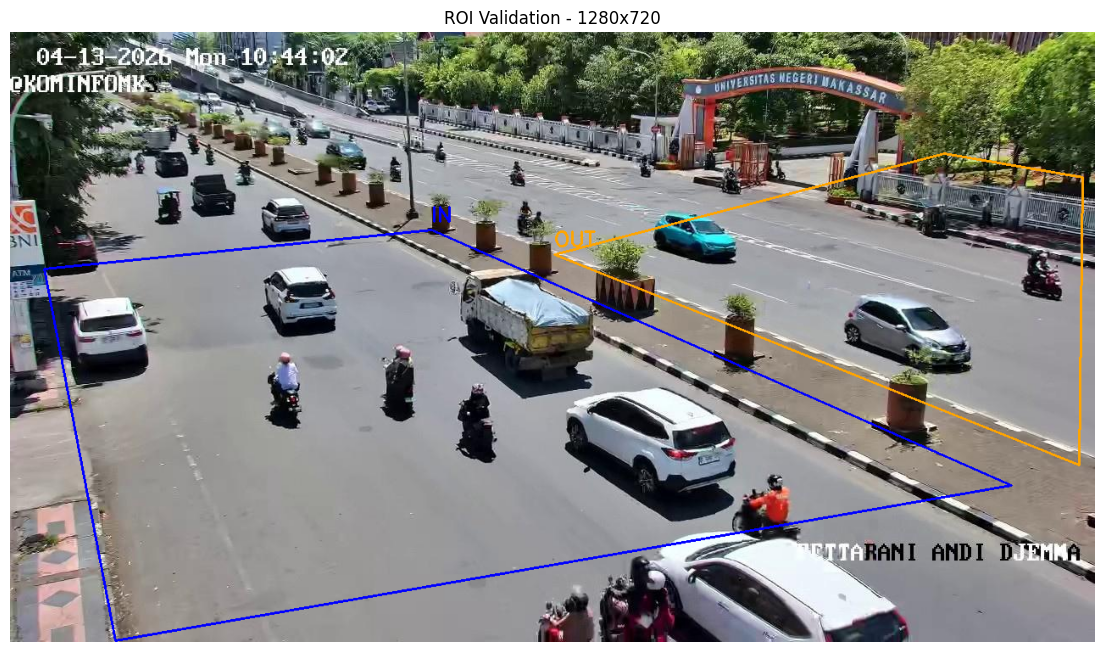

In [11]:
# CELL 9 - VISUALISASI ROI

import matplotlib.pyplot as plt

valid_dir = DATA_DIR / "valid" / "images"

image_files = sorted(
    p for p in valid_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp", ".webp"]
)

assert image_files, "Tidak ada gambar validation!"

image = cv2.imread(str(image_files[0]))

assert image is not None, "Gambar gagal dibaca!"

h, w = image.shape[:2]

polygons = scale_roi((h, w))

colors = {
    "IN": (255, 0, 0),
    "OUT": (0, 165, 255)
}

for name, polygon in polygons.items():

    polygon = polygon.astype(np.int32)

    cv2.polylines(
        image,
        [polygon],
        True,
        colors[name],
        2
    )

    x, y = polygon[0]

    cv2.putText(
        image,
        name,
        (int(x), int(y) - 10),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        colors[name],
        2
    )

plt.figure(figsize=(14, 8))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title(f"ROI Validation - {w}x{h}")
plt.axis("off")
plt.show()

In [ ]:
# CELL 10 - TRAINING YOLOv12s, FULL-FRAME TRAINING + ROI VALIDATION, EKSPERIMEN DATASET 80:20


from ultralytics import YOLO
import torch


# 1. KONFIGURASI
assert yaml_path.exists(), "File data.yaml tidak ditemukan!"

print("CUDA available:", torch.cuda.is_available())

device = 0 if torch.cuda.is_available() else "cpu"

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# 2. LOAD PRETRAINED MODEL
model = YOLO("yolo12s.pt")


# 3. TRAINING DENGAN ROI VALIDATION
results = model.train(

    # Dataset dan ROI Validator
    data=str(yaml_path),
    trainer=ROITrainer,

    # Training
    epochs=100,
    imgsz=640,
    batch=16,
    patience=20,

    # Reproducibility
    seed=42,
    deterministic=True,

    # Hardware
    device=device,
    workers=0,

    # Validation ROI
    val=True,
    conf=0.001,
    max_det=500,

    # Output
    name="train-yolov12s",
    project=str(BASE_DIR / "runs"),
    verbose=True,
    save=True,
    plots=True,
    exist_ok=False
)


# 4. HASIL TRAINING
print("\nTraining selesai.")

print("Folder hasil:", model.trainer.save_dir)
print("Best model  :", model.trainer.best)
print("Last model  :", model.trainer.last)

CUDA available: True
GPU: NVIDIA GeForce RTX 5060 Laptop GPU
New https://pypi.org/project/ultralytics/8.4.215 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.52  Python-3.11.9 torch-2.12.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8151MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=0.001, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\1-Kuliah\SEKRIPSI\Skripsi_Traffic_Density_Estimation_and_Forecasting\01_Datasets\New_YOLO_Datasets\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, k

Folder training : D:\1-Kuliah\SEKRIPSI\Skripsi_Traffic_Density_Estimation_and_Forecasting\03_Vehicle_Detection\runs\train-yolov12s
Total epoch     : 88
Epoch terakhir  : 88
Best Epoch      : 68


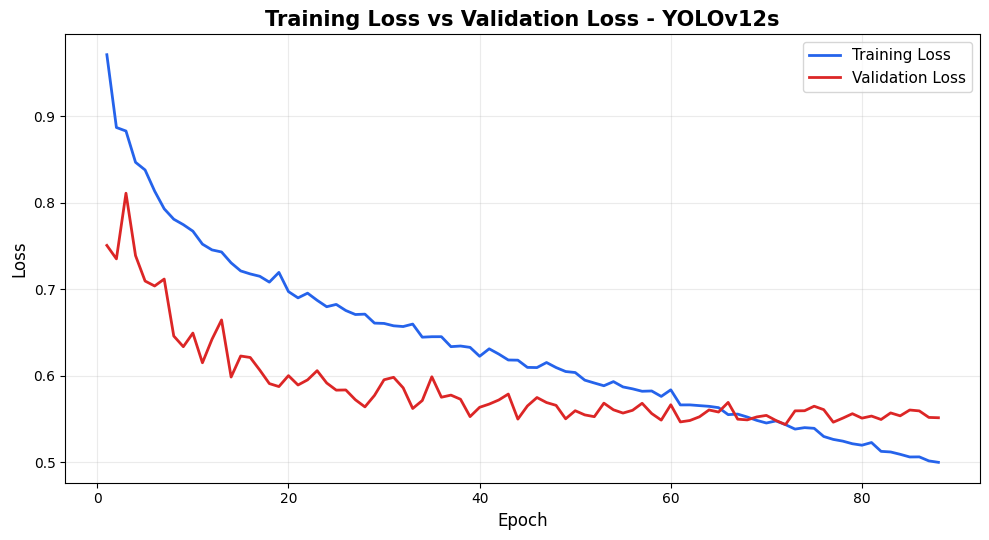

Tersimpan: D:\1-Kuliah\SEKRIPSI\Skripsi_Traffic_Density_Estimation_and_Forecasting\03_Vehicle_Detection\runs\train-yolov12s\grafik_semhas\01_train_val_loss.png


In [ ]:
# CELL 11 - VISUALISASI HASIL TRAINING YOLOv12n


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


# read data hasil training
BASE_DIR = Path(r"D:\1-Kuliah\SEKRIPSI\Skripsi_Traffic_Density_Estimation_and_Forecasting\03_Vehicle_Detection")
run_dir = BASE_DIR / "runs" / "train-yolov12s"
csv_path = run_dir / "results.csv"


# 2. MEMBACA DATA
df = pd.read_csv(csv_path)
df.columns = df.columns.str.strip()
df = df.sort_values("epoch").reset_index(drop=True)

output_dir = run_dir / "grafik_semhas"
output_dir.mkdir(parents=True, exist_ok=True)

# penentuan best epoch berdasarkan mAP50-95(B)
best_idx = df["metrics/mAP50-95(B)"].idxmax()
best_epoch = int(df.loc[best_idx, "epoch"])

total_epoch = len(df)
last_epoch = int(df["epoch"].max())

print(f"Folder training : {run_dir}")
print(f"Total epoch     : {len(df)}")
print(f"Epoch terakhir  : {df['epoch'].max()}")
print(f"Best Epoch      : {best_epoch}")


# grafik training loss vs validation loss
plt.figure(figsize=(10, 5.5))

plt.plot(
    df["epoch"],
    df["train/Loss"],
    label="Training Loss",
    color="#2563EB",
    linewidth=2
)

plt.plot(
    df["epoch"],
    df["val/Loss"],
    label="Validation Loss",
    color="#DC2626",
    linewidth=2
)

plt.title(
    "Training Loss vs Validation Loss - YOLOv12s",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss", fontsize=12)

plt.grid(True, alpha=0.25)
plt.legend(fontsize=11)
plt.tight_layout()

save_path = output_dir / "01_train_val_loss.png"
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("Tersimpan:", save_path)



In [ ]:
# CELL 12 - SIMPAN KONFIGURASI ROI

import json
from pathlib import Path

# Ambil folder training yang sedang digunakan
best_path = run_dir / "weights" / "best.pt"
last_path = run_dir / "weights" / "last.pt"

assert best_path.exists(), f"best.pt tidak ditemukan: {best_path}"

roi_config = {
    "reference_width": ROI_REF_W,
    "reference_height": ROI_REF_H,
    "roi_in": ROI_IN,
    "roi_out": ROI_OUT,
    "filter_method": "bounding_box_center",
    "checkpoint_metric": "ROI mAP50-95",
    "data_yaml": str(yaml_path)
}

config_path = run_dir / "roi_config.json"

with open(config_path, "w") as f:
    json.dump(roi_config, f, indent=4)

print("Folder eksperimen:", run_dir)
print("Best checkpoint :", best_path)
print("Last checkpoint :", last_path)
print("ROI config      :", config_path)
print("File tersimpan  :", config_path.exists())


Folder eksperimen: D:\1-Kuliah\SEKRIPSI\Skripsi_Traffic_Density_Estimation_and_Forecasting\03_Vehicle_Detection\runs\train-yolov12s
Best checkpoint : D:\1-Kuliah\SEKRIPSI\Skripsi_Traffic_Density_Estimation_and_Forecasting\03_Vehicle_Detection\runs\train-yolov12s\weights\best.pt
Last checkpoint : D:\1-Kuliah\SEKRIPSI\Skripsi_Traffic_Density_Estimation_and_Forecasting\03_Vehicle_Detection\runs\train-yolov12s\weights\last.pt
ROI config      : D:\1-Kuliah\SEKRIPSI\Skripsi_Traffic_Density_Estimation_and_Forecasting\03_Vehicle_Detection\runs\train-yolov12s\roi_config.json
File tersimpan  : True


In [ ]:
# CELL 13 - FINAL ROI VALIDATION

best_model = YOLO(str(best_path))

val_results = best_model.val(
    validator=ROIValidator,
    data=str(yaml_path),
    split="val",
    imgsz=640,
    batch=16,
    conf=0.001,
    max_det=500,
    device=0,
    workers=0,
    plots=True,
    project=str(BASE_DIR / "evaluation" /"evaluation_roi_yolov12s"),
    name="validation"
)

print("\nHASIL VALIDATION ROI:")

print(f"Precision : {val_results.box.mp:.4f}")
print(f"Recall    : {val_results.box.mr:.4f}")
print(f"mAP50     : {val_results.box.map50:.4f}")
print(f"mAP50-95  : {val_results.box.map:.4f}")

if len(val_results.box.f1) > 0:
    print(f"Mean F1   : {np.mean(val_results.box.f1):.4f}")

Ultralytics 8.4.52  Python-3.11.9 torch-2.12.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8151MiB)
YOLOv12s summary (fused): 159 layers, 9,232,428 parameters, 0 gradients, 21.2 GFLOPs
val: Fast image access  (ping: 0.10.0 ms, read: 773.9129.7 MB/s, size: 166.6 KB)
val: Scanning D:\1-Kuliah\SEKRIPSI\Skripsi_Traffic_Density_Estimation_and_Forecasting\01_Datasets\New_YOLO_Datasets\valid\labels.cache... 200 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 200/200  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 2.8it/s 4.7s0.3s
ROI Validation | GT total: 3349 | GT dalam ROI: 2066 | Prediksi dalam ROI: 2379
                   all        200       2066      0.966      0.982      0.987      0.903
                   bus         53         53      0.975      0.981      0.985      0.976
                 mobil        194        652      0.988      0.982      0.991      0.916
                 motor        199       12


confusion_matrix.png


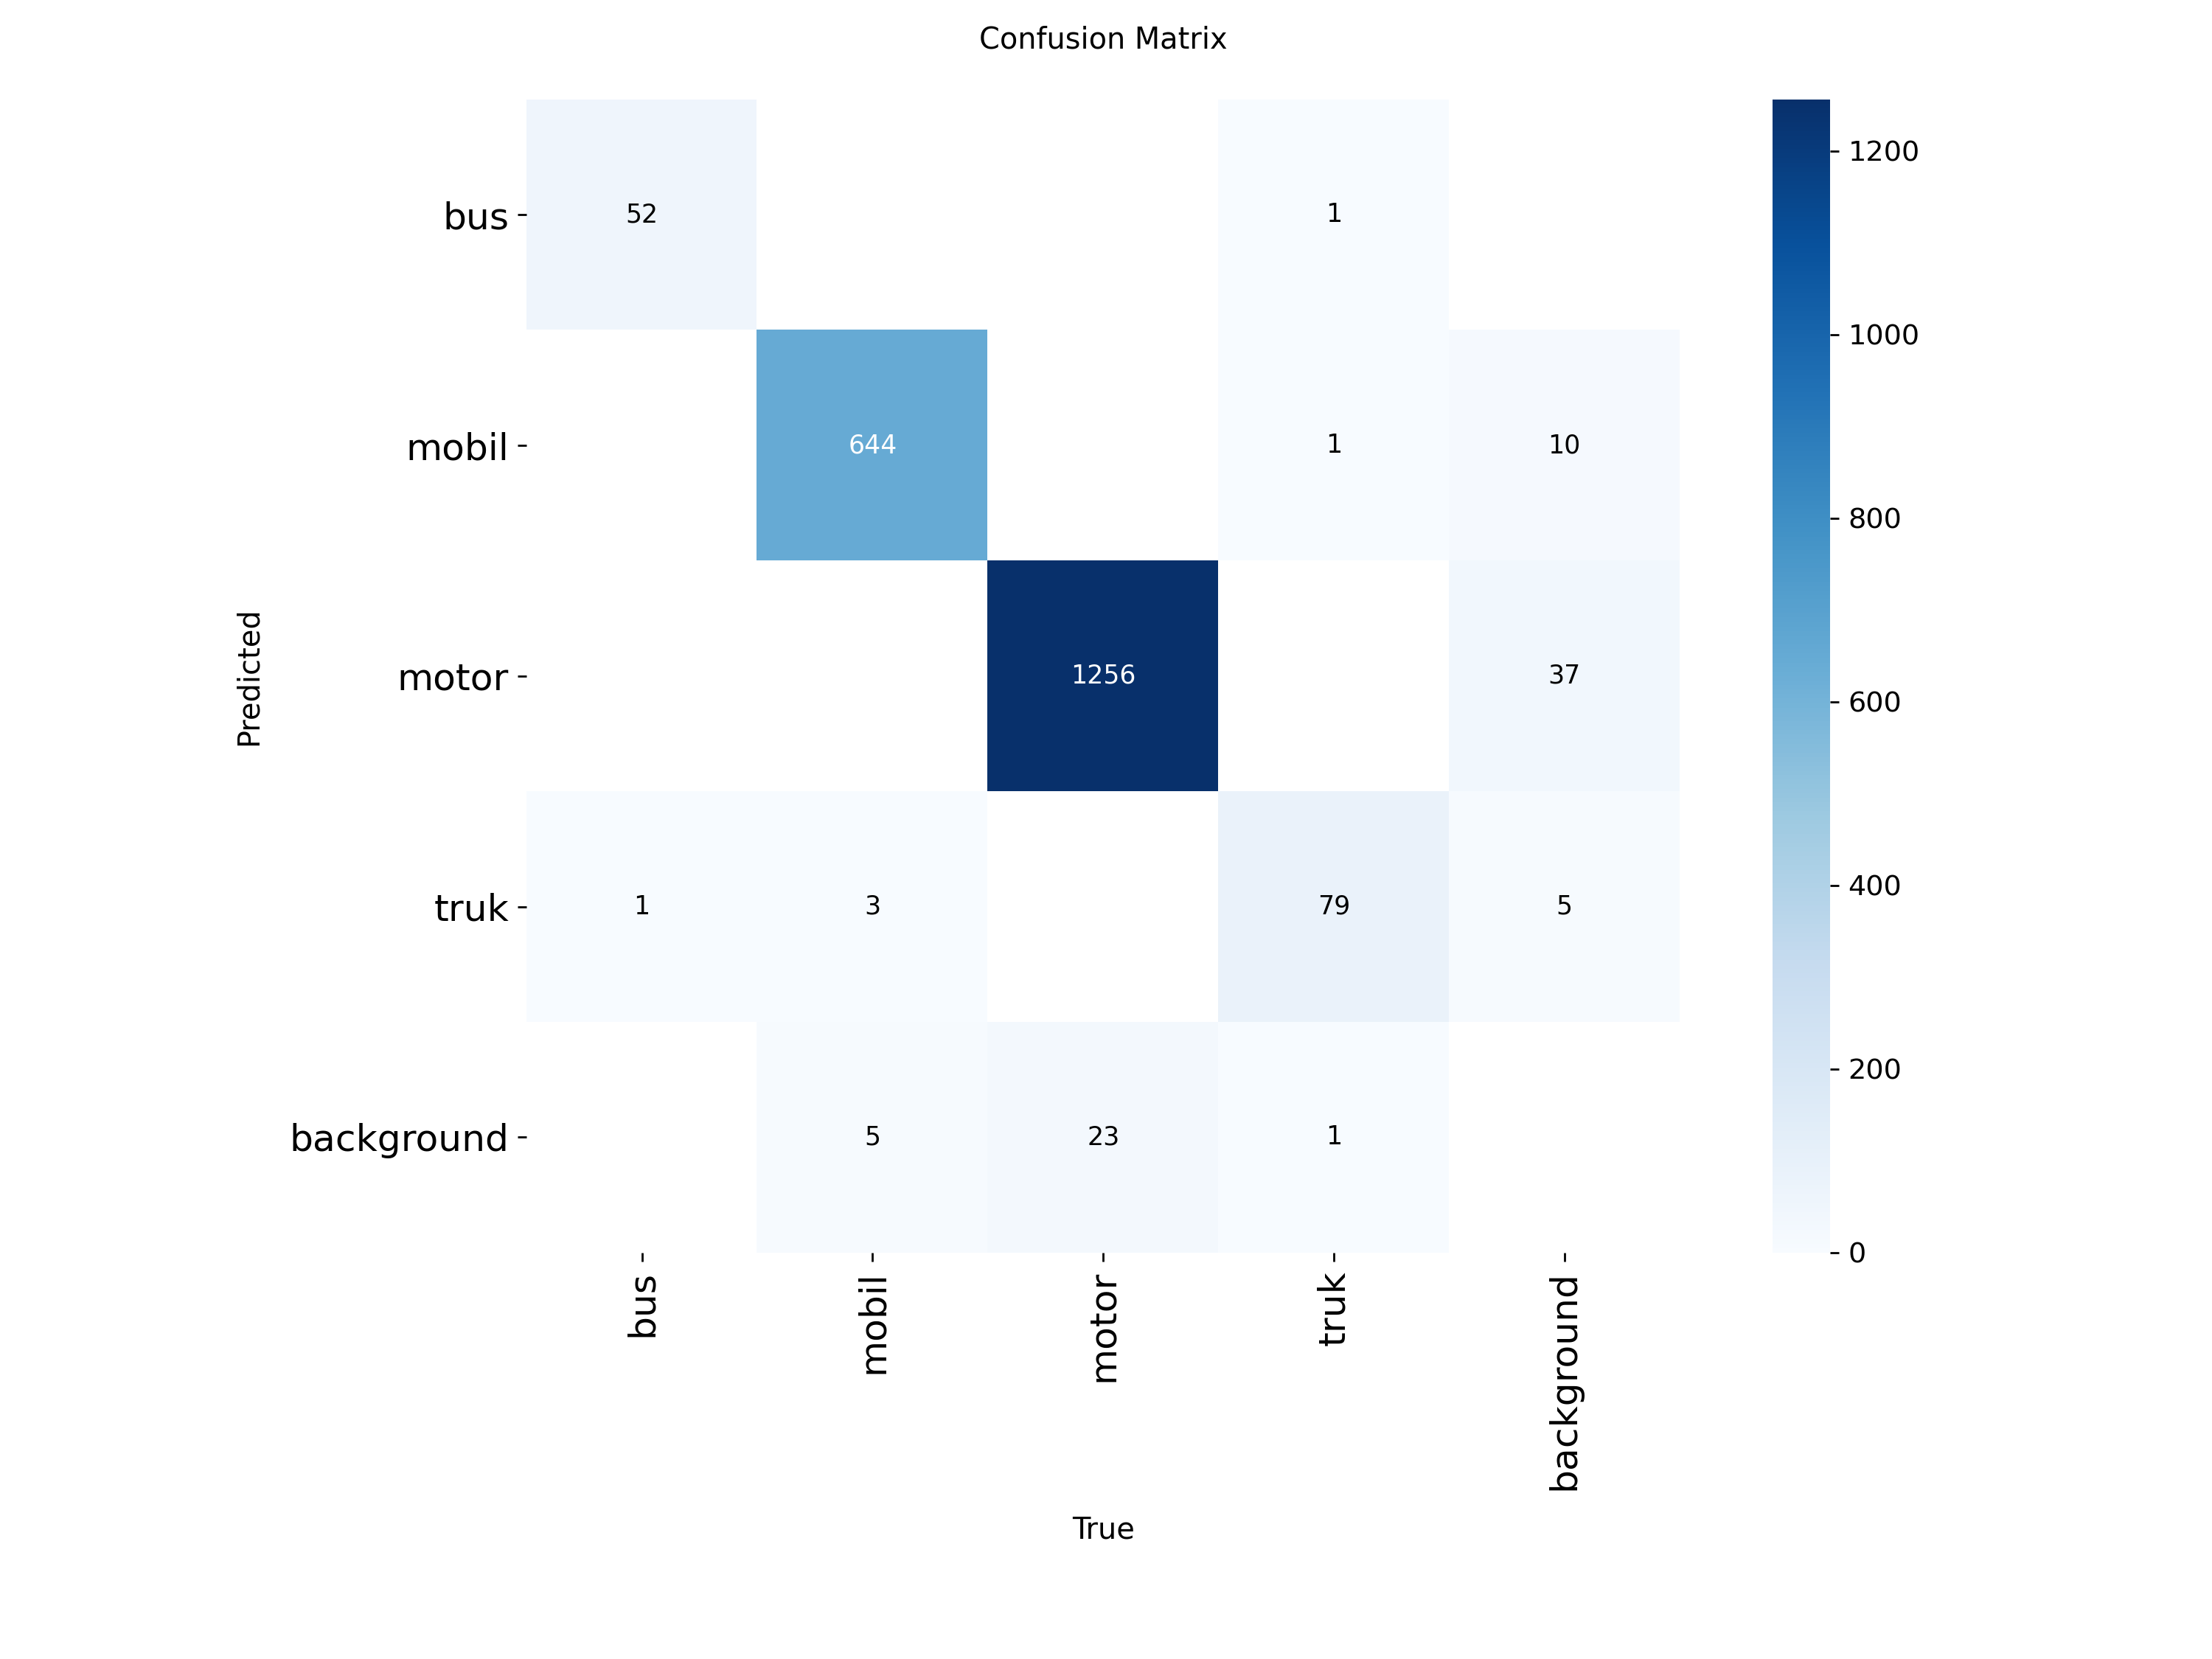


confusion_matrix_normalized.png


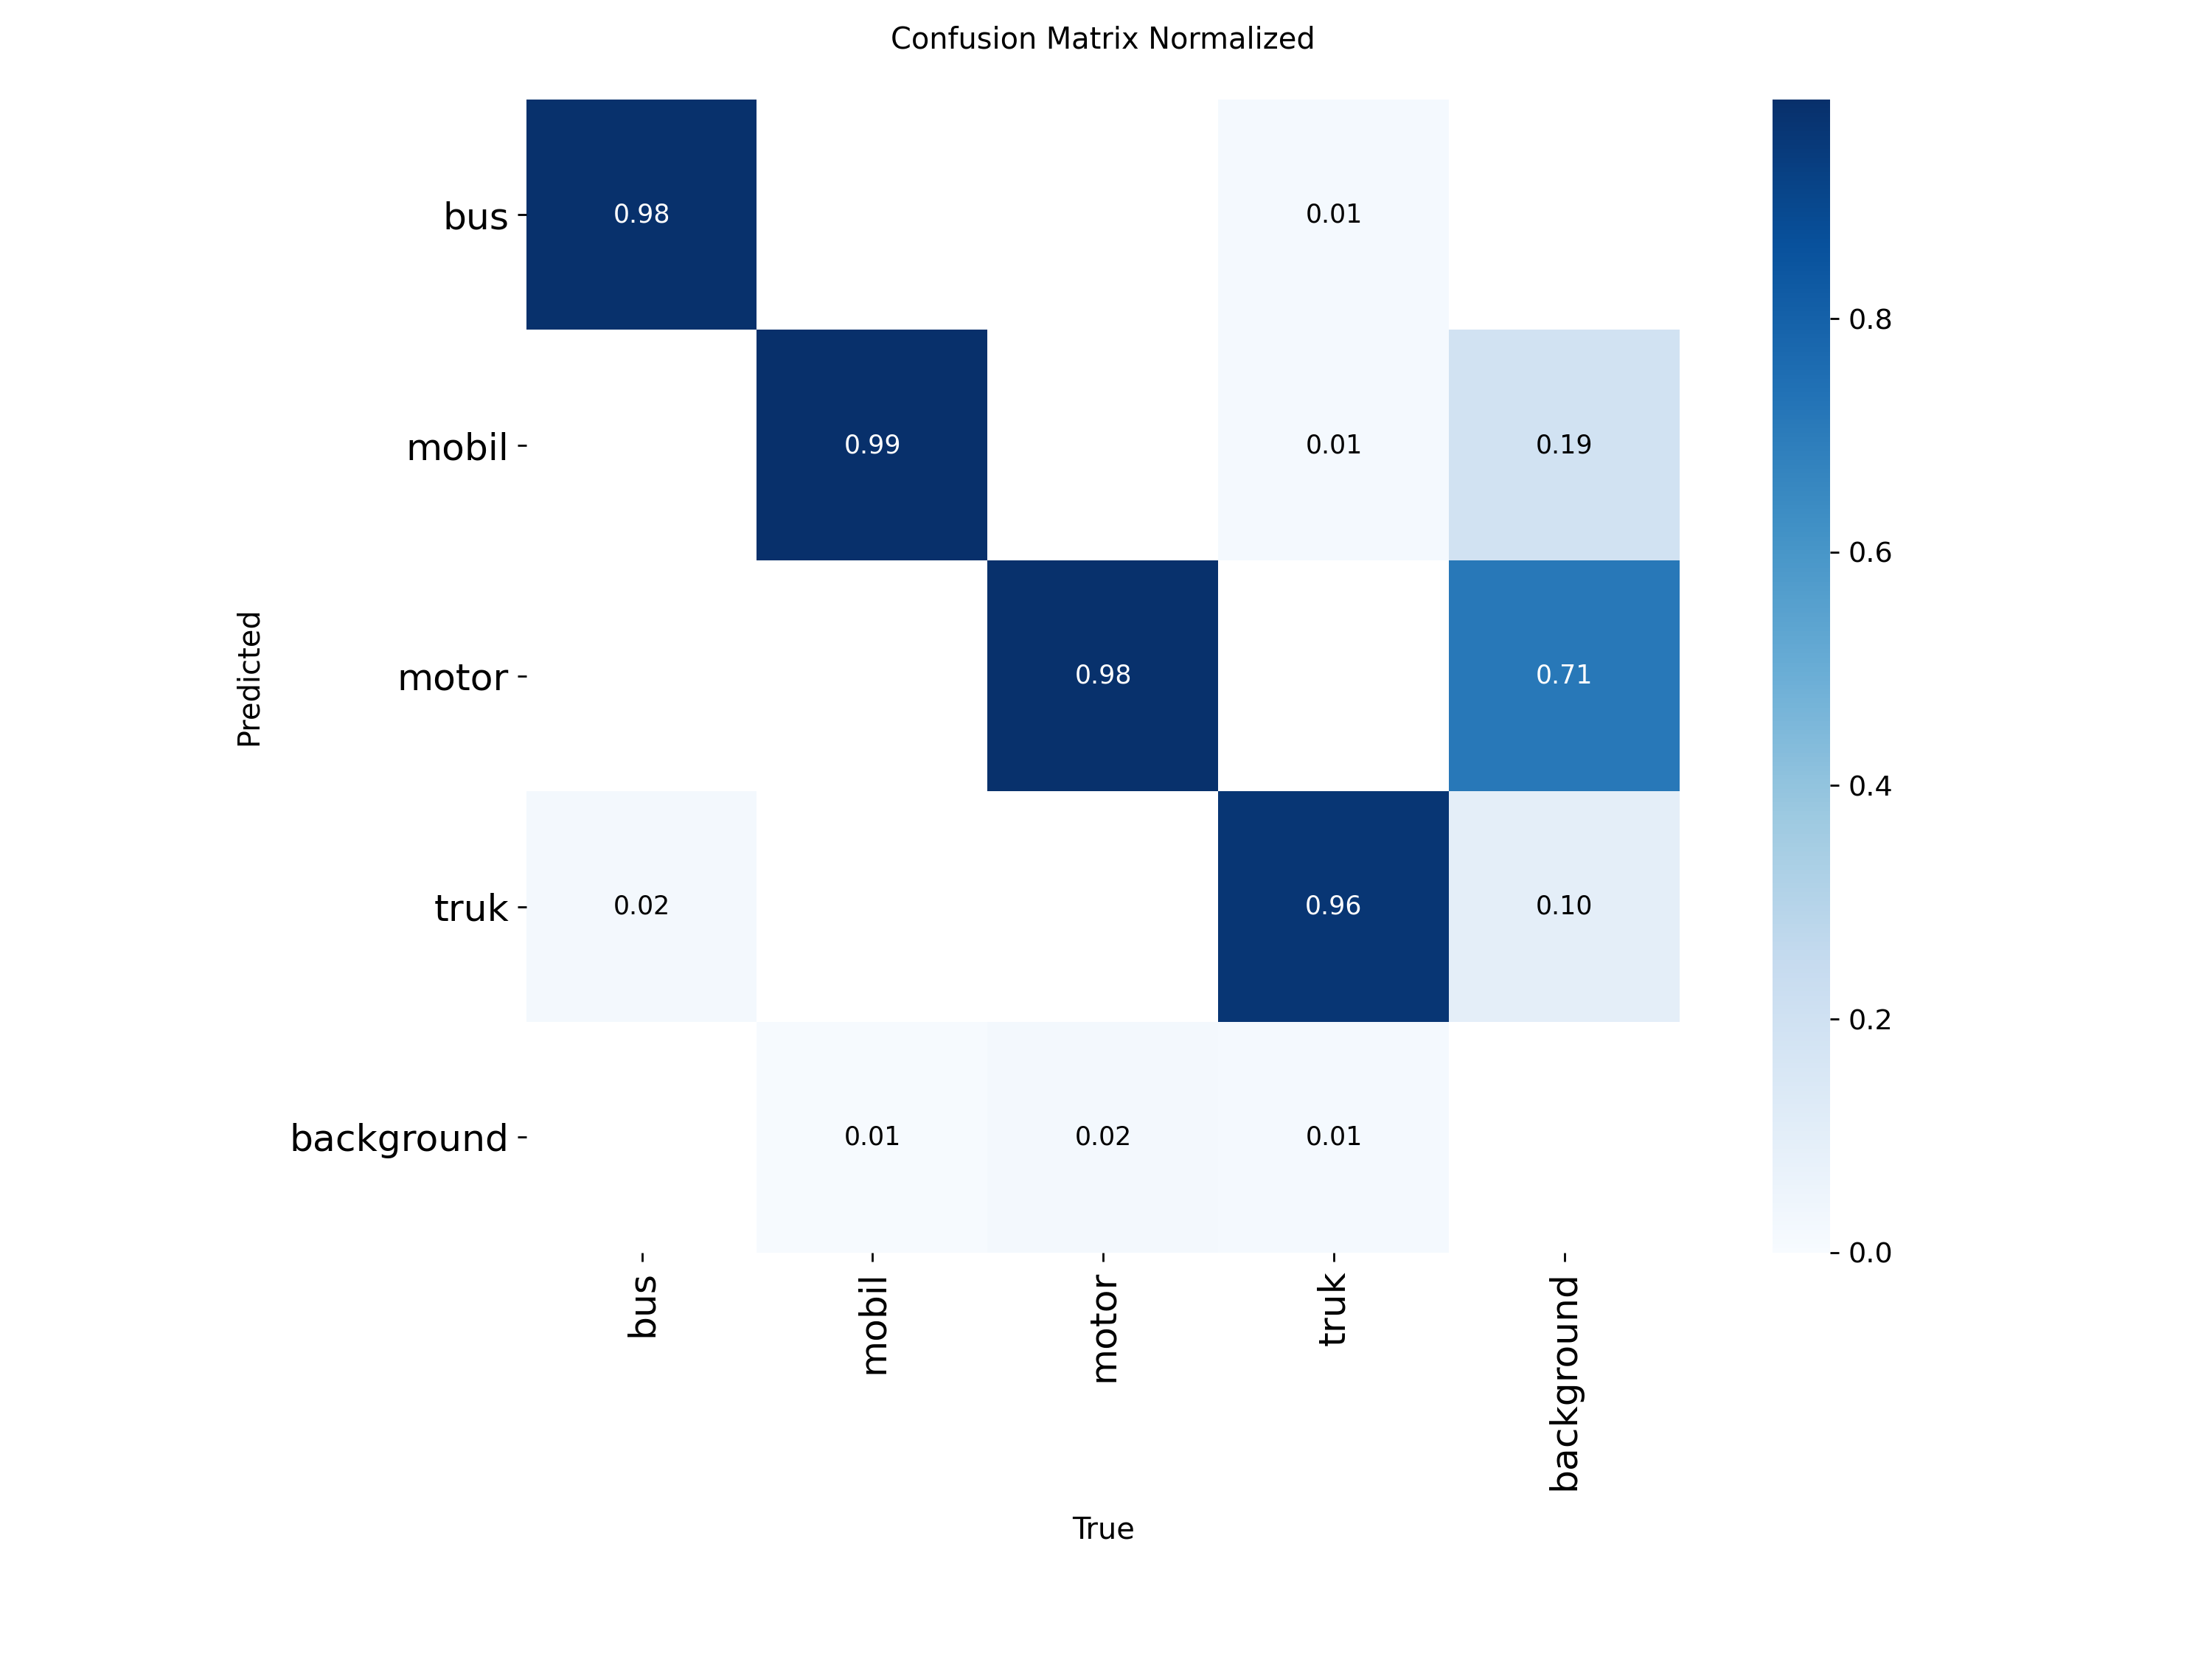


BoxPR_curve.png


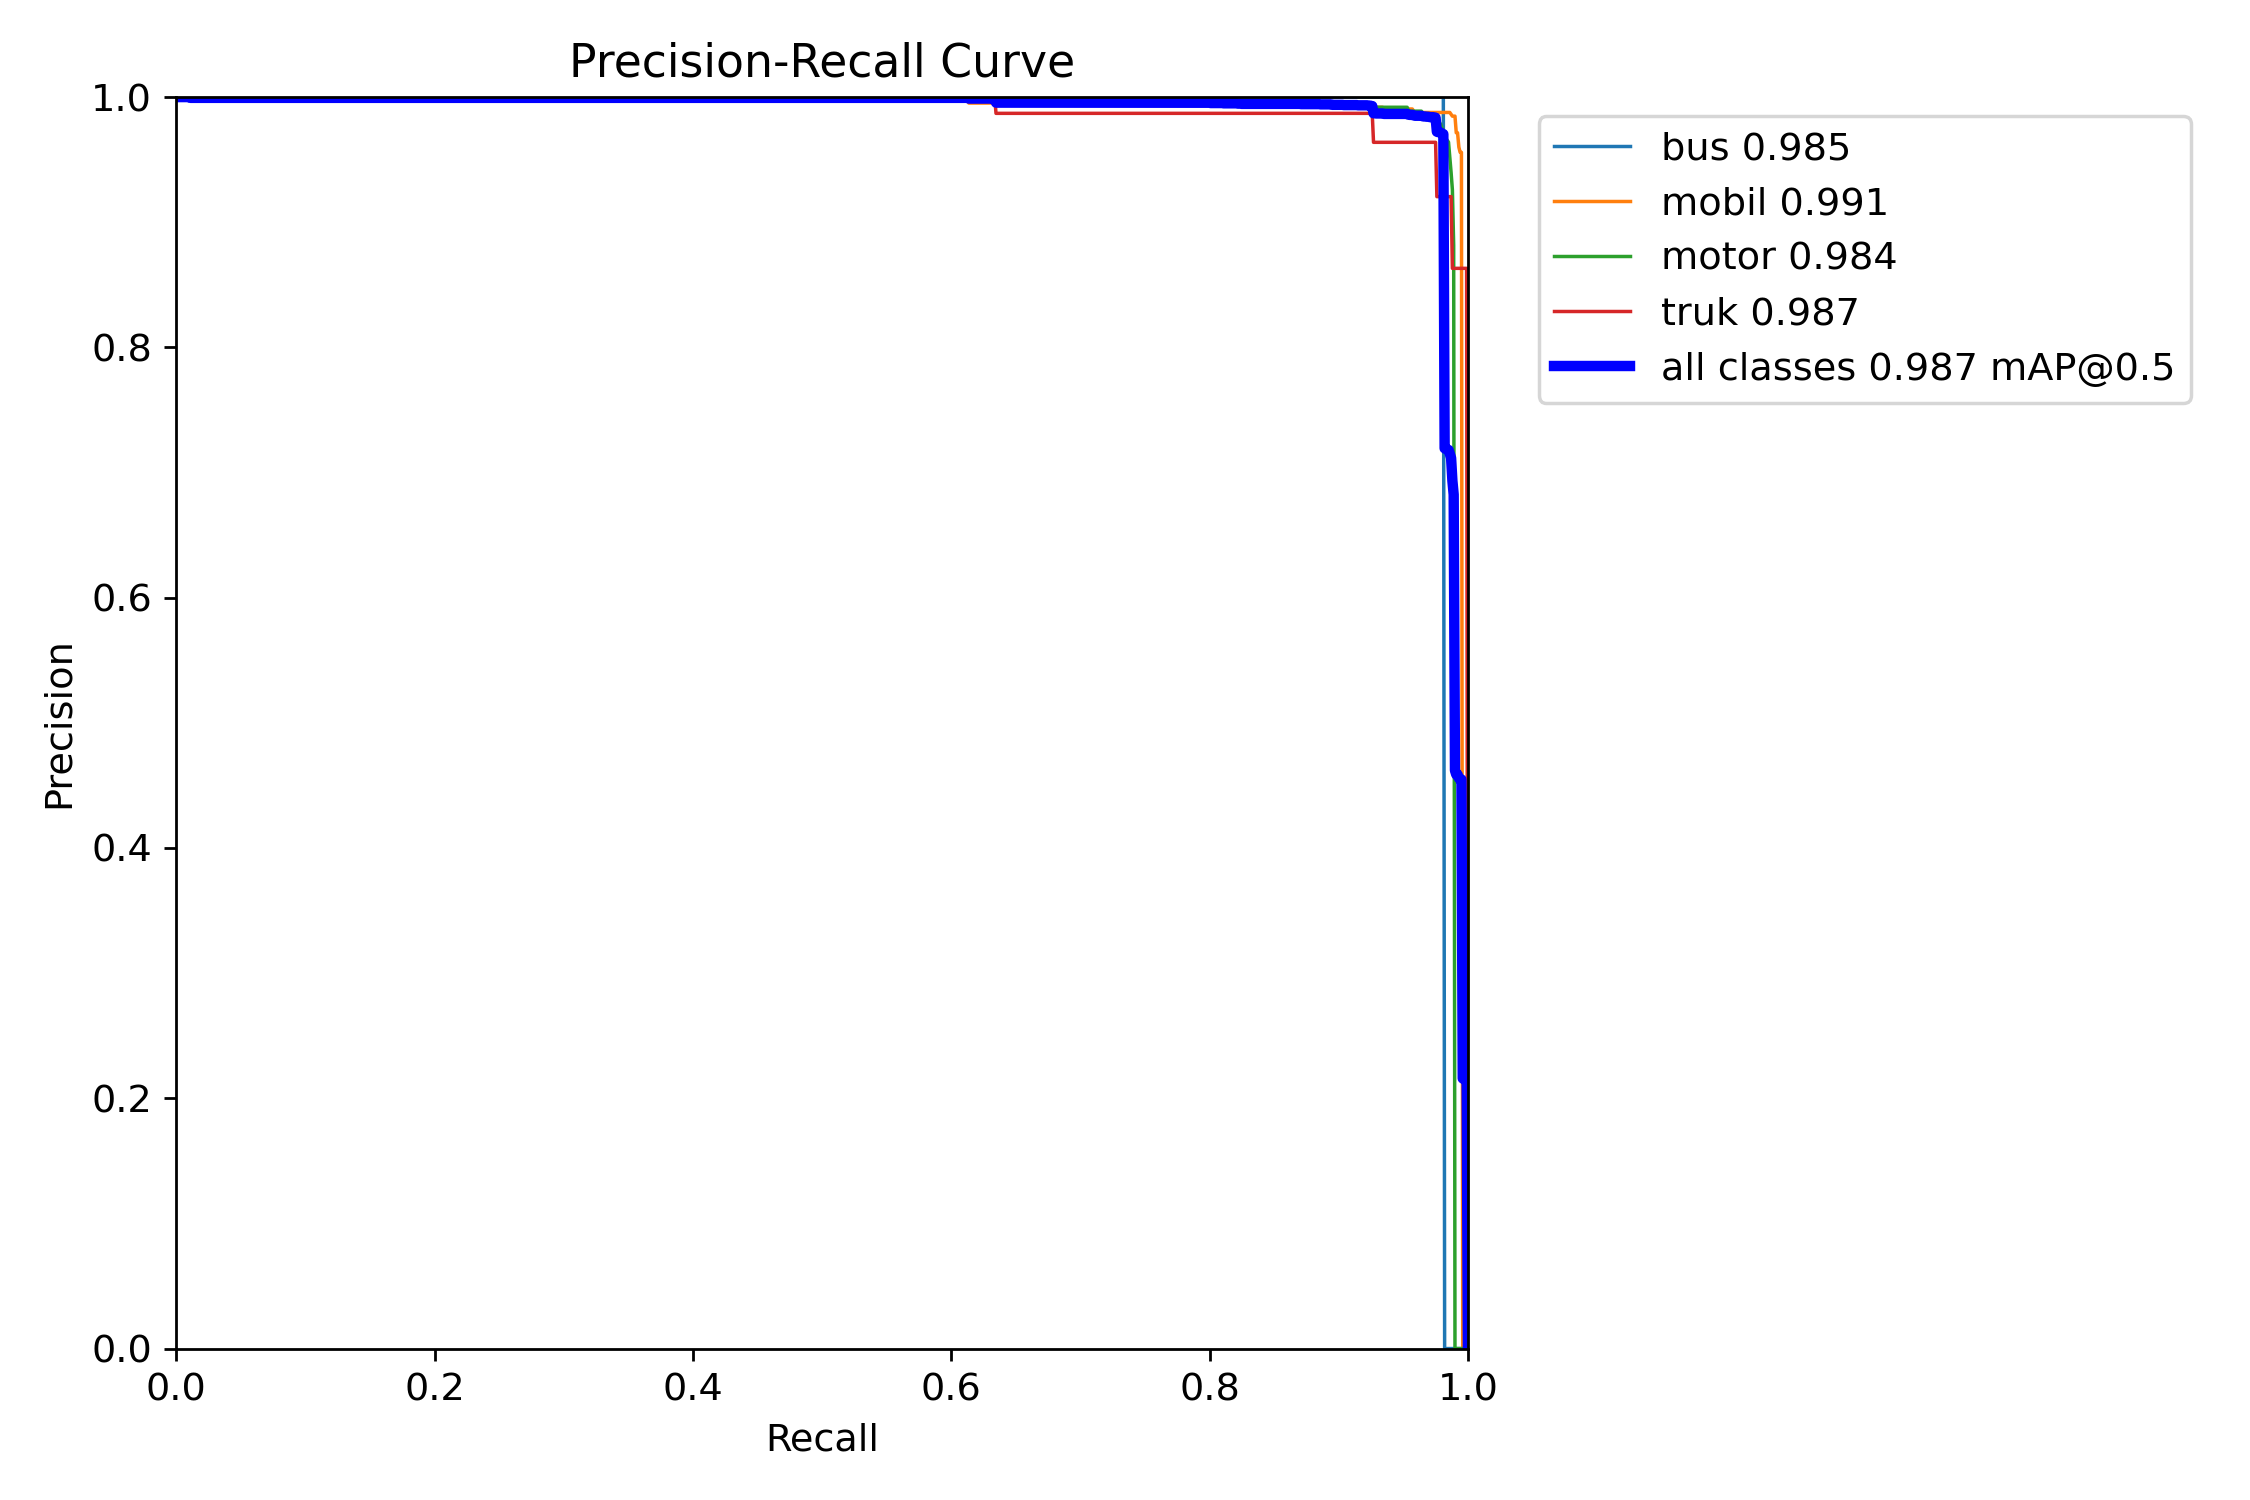


BoxF1_curve.png


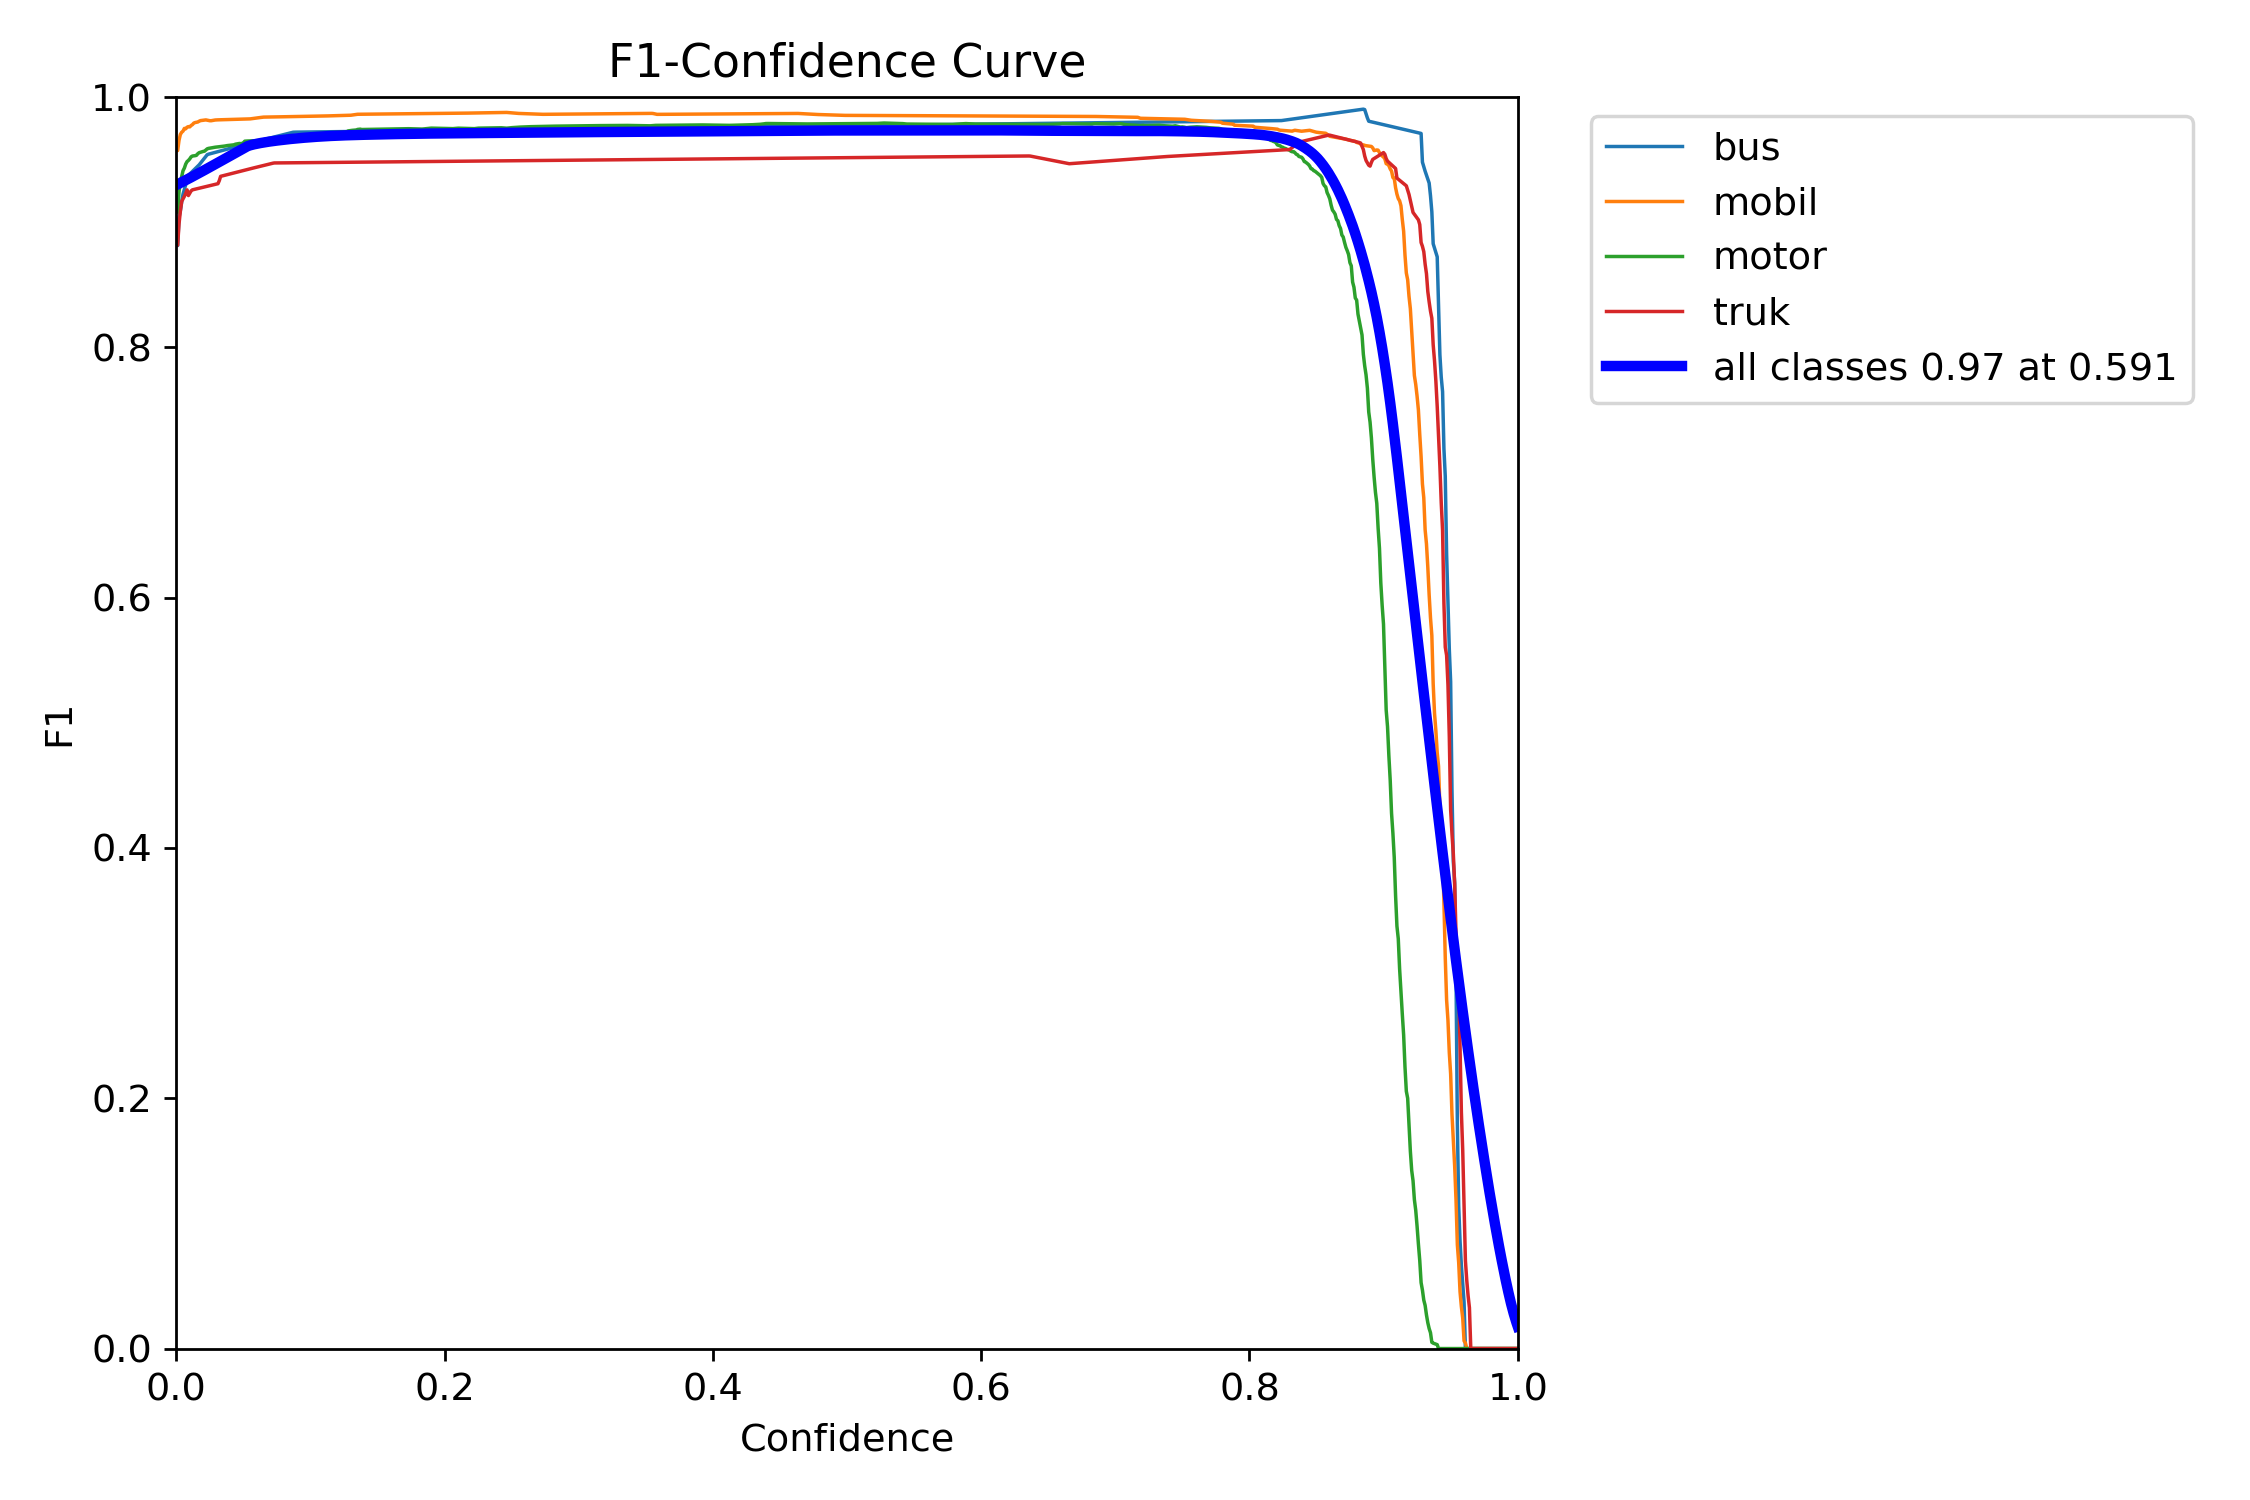

In [16]:
from IPython.display import display, Image
from pathlib import Path

# Daftar grafik
files = [
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "BoxPR_curve.png",
    "BoxF1_curve.png"
]

# Tampilkan grafik
for file in files:
    img_path = run_dir / file

    if img_path.exists():
        print(f"\n{file}")
        display(Image(filename=str(img_path), width=800))
    else:
        print(f"File tidak ditemukan: {img_path}")

MODEL_PATH = r"D:\1-Kuliah\SEKRIPSI\1234-new-train-model-yolov12\runs\yolov12n-roi-validation\weights\best.pt"